# Student Segmentation with K-Means

This notebook groups students using academic-context, demographic, and behavioral variables from the UCI Student Performance dataset. Final grades (`G3`) and earlier grades (`G1`, `G2`) are excluded from clustering and used only after fitting to help interpret the groups. The clusters are exploratory patterns in this sample, not verified student categories.

In [1]:
from pathlib import Path
import os
import warnings

os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## 1. Load and inspect the data

In [2]:
data_path = Path('data/student-performance-uci/student-mat.csv')
students = pd.read_csv(data_path, sep=';')

print(f'Shape: {students.shape}')
display(students.head())
students.info()

Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [3]:
display(students.describe(include='all').T)
print(f'Total missing values: {students.isna().sum().sum()}')
print(f'Duplicate rows: {students.duplicated().sum()}')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Total missing values: 0
Duplicate rows: 0


## 2. Cleaning and feature selection

No missing values or duplicates are present. The workflow nevertheless uses imputers for robustness. Selected features cover background, study habits, support, social behavior, health, and attendance. `G1`, `G2`, and `G3` are excluded to avoid defining groups directly by academic results.

In [4]:
students = students.drop_duplicates().reset_index(drop=True)

selected_features = [
    'school', 'sex', 'age', 'address', 'famsize', 'Pstatus',
    'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
    'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences'
]
X = students[selected_features].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Numeric features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet']


## 3. Exploratory analysis

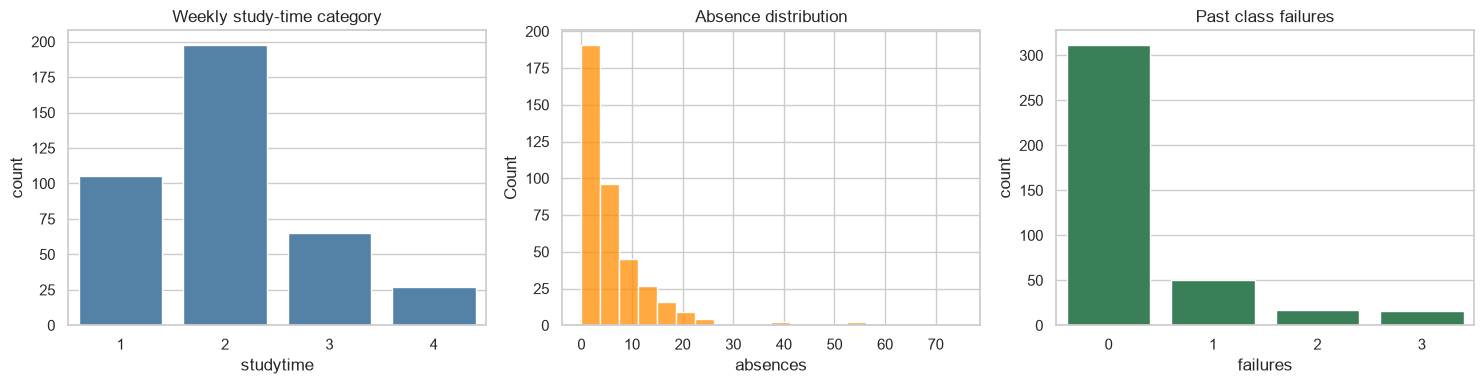

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=students, x='studytime', ax=axes[0], color='steelblue')
axes[0].set_title('Weekly study-time category')
sns.histplot(data=students, x='absences', bins=20, ax=axes[1], color='darkorange')
axes[1].set_title('Absence distribution')
sns.countplot(data=students, x='failures', ax=axes[2], color='seagreen')
axes[2].set_title('Past class failures')
plt.tight_layout()
plt.show()

## 4. Encode and scale features

Numeric variables are median-imputed and standardized. Categorical variables are mode-imputed, one-hot encoded, and then scaled so encoded categories do not dominate solely because of their representation.

In [6]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

X_processed = preprocessor.fit_transform(X)
print(f'Processed feature matrix: {X_processed.shape}')

Processed feature matrix: (395, 35)


## 5. Elbow method and silhouette scores

K values from 2 to 8 are compared. Inertia supports the elbow plot, while the silhouette score measures how compact and separated the clusters are.

,K,Inertia,Silhouette Score
0,2,"12,687.1",0.1695
1,3,"11,898.5",0.1241
2,4,"11,083.9",0.0938
3,5,"10,438.3",0.0972
4,6,"9,844.9",0.0997
5,7,"9,446.7",0.0928
6,8,"9,238.5",0.0765


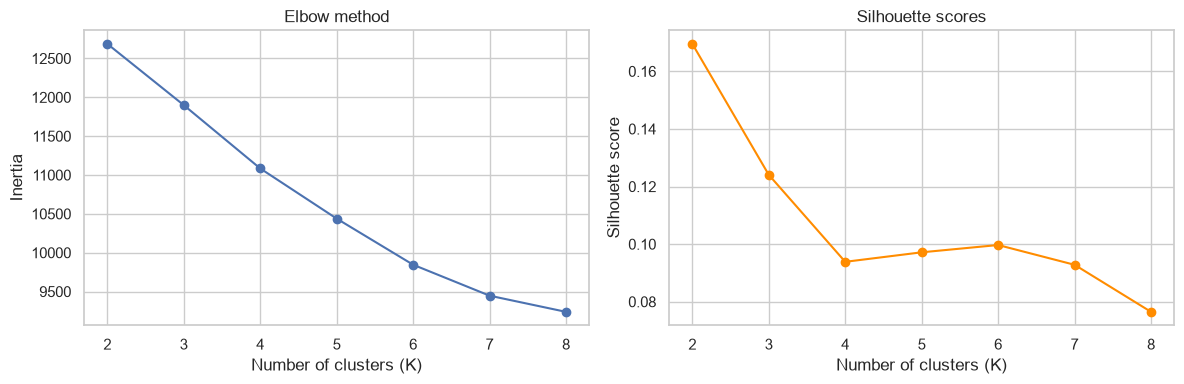

In [7]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_processed)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_processed, labels))

selection_results = pd.DataFrame({
    'K': list(k_values), 'Inertia': inertias, 'Silhouette Score': silhouette_scores
})
display(selection_results.style.format({'Inertia': '{:,.1f}', 'Silhouette Score': '{:.4f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set(title='Elbow method', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(list(k_values), silhouette_scores, marker='o', color='darkorange')
axes[1].set(title='Silhouette scores', xlabel='Number of clusters (K)', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

## 6. Fit the selected K-Means model

The selected K is the tested value with the highest silhouette score. This transparent rule is appropriate here because the elbow may be gradual.

In [8]:
best_index = int(np.argmax(silhouette_scores))
selected_k = list(k_values)[best_index]
best_silhouette = silhouette_scores[best_index]

kmeans = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
students['cluster'] = kmeans.fit_predict(X_processed)

print(f'Selected number of clusters: {selected_k}')
print(f'Best silhouette score: {best_silhouette:.4f}')
display(students['cluster'].value_counts().sort_index().to_frame('students'))

Selected number of clusters: 2
Best silhouette score: 0.1695


,students
cluster,
0,82
1,313


## 7. PCA visualization

PCA projects the processed features into two dimensions for visualization only. K-Means was fitted using the full processed feature matrix.

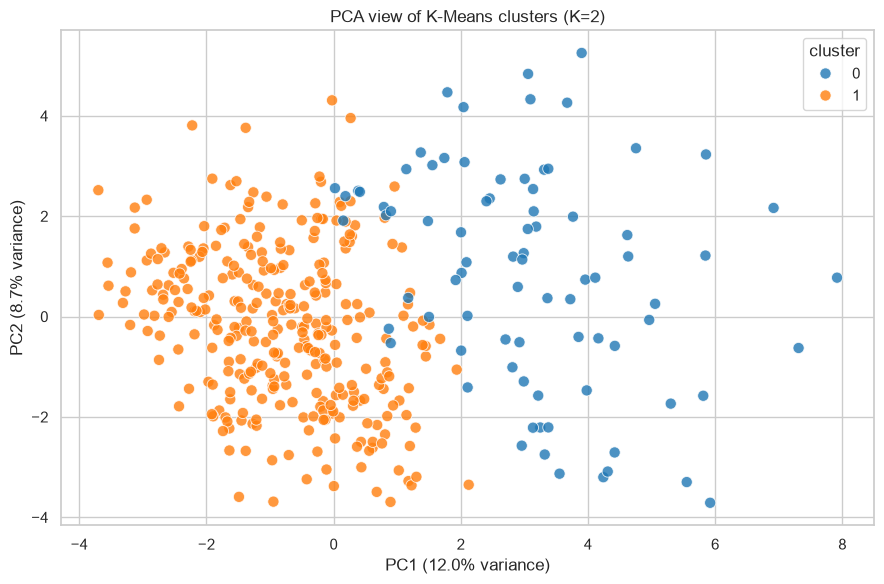

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(X_processed)
pca_df = pd.DataFrame({'PC1': components[:, 0], 'PC2': components[:, 1], 'cluster': students['cluster']})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='cluster', palette='tab10', s=65, alpha=0.8)
plt.title(f'PCA view of K-Means clusters (K={selected_k})')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()

## 8. Cluster profiles

The table summarizes variables in their original units. Mean `G3` is included only as an external interpretation variable; it did not influence cluster formation.

In [10]:
profile_columns = [
    'age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3'
]
cluster_profile = students.groupby('cluster')[profile_columns].mean().round(2)
cluster_profile.insert(0, 'size', students.groupby('cluster').size())
display(cluster_profile)

categorical_profile = pd.DataFrame({
    'female_%': students.groupby('cluster')['sex'].apply(lambda s: (s == 'F').mean() * 100),
    'higher_education_goal_%': students.groupby('cluster')['higher'].apply(lambda s: (s == 'yes').mean() * 100),
    'internet_%': students.groupby('cluster')['internet'].apply(lambda s: (s == 'yes').mean() * 100),
    'school_support_%': students.groupby('cluster')['schoolsup'].apply(lambda s: (s == 'yes').mean() * 100),
    'family_support_%': students.groupby('cluster')['famsup'].apply(lambda s: (s == 'yes').mean() * 100),
}).round(1)
display(categorical_profile)

,size,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G3
cluster,,,,,,,,,,,,,,,
0,82,17.77,2.20,2.00,1.90,1.71,0.71,3.91,3.39,3.22,1.74,2.74,3.68,4.50,8.93
1,313,16.42,2.89,2.66,1.33,2.12,0.24,3.95,3.19,3.08,1.41,2.17,3.52,6.03,10.81


,female_%,higher_education_goal_%,internet_%,school_support_%,family_support_%
cluster,,,,,
0,40.2,76.8,57.3,1.2,31.7
1,55.9,99.7,90.1,16.0,69.0


## 9. Interpretation

In [11]:
overall = students[profile_columns].mean()
for cluster_id, row in cluster_profile.iterrows():
    traits = []
    if row['studytime'] > overall['studytime'] + 0.15:
        traits.append('above-average study time')
    elif row['studytime'] < overall['studytime'] - 0.15:
        traits.append('below-average study time')
    if row['failures'] > overall['failures'] + 0.15:
        traits.append('more past failures')
    elif row['failures'] < overall['failures'] - 0.15:
        traits.append('fewer past failures')
    if row['absences'] > overall['absences'] + 1:
        traits.append('more absences')
    elif row['absences'] < overall['absences'] - 1:
        traits.append('fewer absences')
    if row['Walc'] > overall['Walc'] + 0.2:
        traits.append('higher weekend alcohol use')
    elif row['Walc'] < overall['Walc'] - 0.2:
        traits.append('lower weekend alcohol use')
    if row['goout'] > overall['goout'] + 0.2:
        traits.append('more frequent social outings')
    elif row['goout'] < overall['goout'] - 0.2:
        traits.append('less frequent social outings')
    if not traits:
        traits.append('values close to the sample average on the highlighted measures')
    print(f"Cluster {cluster_id} (n={int(row['size'])}): " + ', '.join(traits) + f". Mean G3 = {row['G3']:.2f} (interpretation only).")

print()
print('These descriptions summarize relative patterns in this dataset and should not be treated as fixed or causal student categories.')

Cluster 0 (n=82): below-average study time, more past failures, fewer absences, higher weekend alcohol use. Mean G3 = 8.93 (interpretation only).
Cluster 1 (n=313): values close to the sample average on the highlighted measures. Mean G3 = 10.81 (interpretation only).

These descriptions summarize relative patterns in this dataset and should not be treated as fixed or causal student categories.


## 10. Conclusion

K-Means provides an exploratory segmentation based on background, study, support, social, health, and attendance features. The selected solution is based on the strongest silhouette score among the tested K values. The moderate overlap visible in the PCA plot and the silhouette value should be considered when interpreting the groups.